# Mobile Product Segmentation and Recommendation System
End-to-end pipeline on the Global Mobile Reviews dataset (`Mobile_Reviews_Sentiment_null.csv`).

## 1. Python & Data Processing

In [2]:
import os, re, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_PATH = "Mobile_Reviews_Sentiment_null.csv"   # <-- change if needed

## 2. CSV to DataFrame Conversion

In [3]:
df = pd.read_csv('Mobile Reviews Sentiment null.csv')
print("Shape:", df.shape)
print(df.dtypes)
df.head()

Shape: (50000, 22)
review_id                 int64
customer_name               str
age                       int64
brand                       str
model                       str
price_usd               float64
price_local                 str
currency                    str
exchange_rate_to_usd    float64
rating                  float64
sentiment                   str
country                     str
language                    str
review_date                 str
verified_purchase          bool
battery_life_rating       int64
camera_rating             int64
performance_rating        int64
design_rating             int64
display_rating            int64
helpful_votes             int64
source                      str
dtype: object


,review_id,customer_name,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,...,language,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.31,₹27996.73,INR,83.00,2.0,...,Hindi,11/6/2023,True,1,1,3,2,1,1,Amazon
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.78,R$1754.35,BRL,5.70,4.0,...,Portuguese,3/30/2023,True,3,2,4,3,2,5,Flipkart
2,3,Pahal Balay,27,Google,Pixel 6,864.53,₹71755.99,INR,83.00,4.0,...,Hindi,12/7/2022,True,3,5,3,2,4,8,AliExpress
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.94,د.إ2425.65,AED,3.67,3.0,...,English,3/11/2025,False,1,3,2,1,2,3,Amazon
4,5,Yago Leão,38,Motorola,Edge 50,792.13,R$4515.14,BRL,5.70,3.0,...,Portuguese,9/29/2023,True,3,3,2,2,1,0,BestBuy


## 3. Data Cleaning (Handling Missing Values & Duplicates)

In [4]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("Rows with at least one missing value:", df.isnull().any(axis=1).sum())
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicates ignoring review_id:", df.drop(columns=["review_id"]).duplicated().sum())

Missing values per column:
price_usd      2450
price_local    2431
rating         2453
sentiment      2445
source         2448
dtype: int64
Rows with at least one missing value: 11058
Exact duplicate rows: 0
Duplicates ignoring review_id: 0


In [5]:
df = df.copy()
df = df.drop_duplicates().reset_index(drop=True)

# --- Price: price_local is a currency string (e.g. '₹27996.73'); parse it to a number
df["price_local_num"] = pd.to_numeric(
    df["price_local"].str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
df["price_local_num"].describe()

count     41623.000000
mean       9113.194305
std       21664.030917
min         141.090000
25%         552.240000
50%         923.580000
75%        2568.880000
max      124397.080000
Name: price_local_num, dtype: float64

In [6]:
# price_local == price_usd * exchange_rate_to_usd (verified), so each can be rebuilt from the other
ok = df["price_local_num"].notna() & df["price_usd"].notna()
ratio = df.loc[ok, "price_local_num"] / df.loc[ok, "exchange_rate_to_usd"] / df.loc[ok, "price_usd"]
print("price_local / rate / price_usd  -> min %.5f, max %.5f" % (ratio.min(), ratio.max()))

price_local / rate / price_usd  -> min 0.99997, max 1.00003


In [7]:
n_usd_missing = df["price_usd"].isna().sum()
df["price_usd"] = df["price_usd"].fillna(df["price_local_num"] / df["exchange_rate_to_usd"])
print("price_usd missing before: %d, after rebuild from local: %d" % (n_usd_missing, df["price_usd"].isna().sum()))

price_usd missing before: 2450, after rebuild from local: 389


In [8]:
# whatever is still missing (both prices absent) -> median price of the same model
df["price_usd"] = df["price_usd"].fillna(df.groupby("model")["price_usd"].transform("median"))
df["price_local_num"] = df["price_local_num"].fillna(df["price_usd"] * df["exchange_rate_to_usd"]).round(2)
# --- Rating: rebuild from the mean of the five aspect ratings (corr ~0.93 with rating)
aspect_cols = ["battery_life_rating", "camera_rating", "performance_rating", "design_rating", "display_rating"]
df["aspect_mean"] = df[aspect_cols].mean(axis=1)
df["rating"] = df["rating"].fillna(df["aspect_mean"].round()).clip(1, 5)

# --- Sentiment: most frequent sentiment seen for that star rating
mode_map = df.dropna(subset=["sentiment"]).groupby("rating")["sentiment"].agg(lambda s: s.mode().iloc[0])
print("Rating -> sentiment mapping used for imputation:", mode_map.to_dict())
df["sentiment"] = df["sentiment"].fillna(df["rating"].map(mode_map))

# --- Source: categorical, keep an explicit 'Unknown' level rather than inventing a platform
df["source"] = df["source"].fillna("Unknown")

print("Remaining missing values:", int(df[["price_usd","rating","sentiment","source"]].isnull().sum().sum()))

Rating -> sentiment mapping used for imputation: {1.0: 'Negative', 2.0: 'Neutral', 3.0: 'Positive', 4.0: 'Positive', 5.0: 'Positive'}
Remaining missing values: 0


## 4. Data Preprocessing & Feature Engineering

In [9]:
df["review_date"] = pd.to_datetime(df["review_date"])
df["year"] = df["review_date"].dt.year
df["month"] = df["review_date"].dt.month
df["verified_purchase"] = df["verified_purchase"].astype(int)
df["rating"] = df["rating"].astype(int)

df["age_group"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 65],
                         labels=["18-25", "26-35", "36-45", "46-65"])
df["sentiment_score"] = df["sentiment"].map({"Negative": -1, "Neutral": 0, "Positive": 1})
df["is_positive"] = (df["sentiment"] == "Positive").astype(int)
df["engagement_score"] = df["helpful_votes"] * (1 + df["verified_purchase"])   # verified votes count double
df["price_tier"] = pd.qcut(df["price_usd"], 4, labels=["Budget", "Mid", "Upper-mid", "Premium"])

df.to_csv("cleaned_mobile_reviews.csv", index=False)
print(df.shape)
df.head(3).T

(50000, 31)


,0,1,2
review_id,1,2,3
customer_name,Aryan Maharaj,Davi Miguel Sousa,Pahal Balay
age,45,18,27
brand,Realme,Realme,Google
model,Realme 12 Pro,Realme 12 Pro,Pixel 6
price_usd,337.31,307.78,864.53
price_local,₹27996.73,R$1754.35,₹71755.99
currency,INR,BRL,INR
exchange_rate_to_usd,83.0,5.7,83.0
rating,2,4,4


## 5. Exploratory Data Analysis (EDA)

In [10]:
print(df[["age", "price_usd", "rating", "helpful_votes"] + aspect_cols].describe().round(2))
for c in ["brand", "country", "sentiment", "source"]:
    print("\n", c); print(df[c].value_counts())

            age  price_usd    rating  helpful_votes  battery_life_rating  \
count  50000.00   50000.00  50000.00       50000.00             50000.00   
mean      30.08     689.68      3.10           3.64                 2.72   
std        8.93     309.80      1.25           2.43                 1.35   
min       18.00     180.02      1.00           0.00                 1.00   
25%       23.00     450.63      2.00           2.00                 1.00   
50%       29.00     637.52      3.00           3.00                 3.00   
75%       36.00     900.92      4.00           5.00                 4.00   
max       65.00    1499.89      5.00          17.00                 5.00   

       camera_rating  performance_rating  design_rating  display_rating  
count       50000.00            50000.00       50000.00        50000.00  
mean            2.72                2.72           2.71            2.72  
std             1.35                1.35           1.34            1.35  
min             1.0

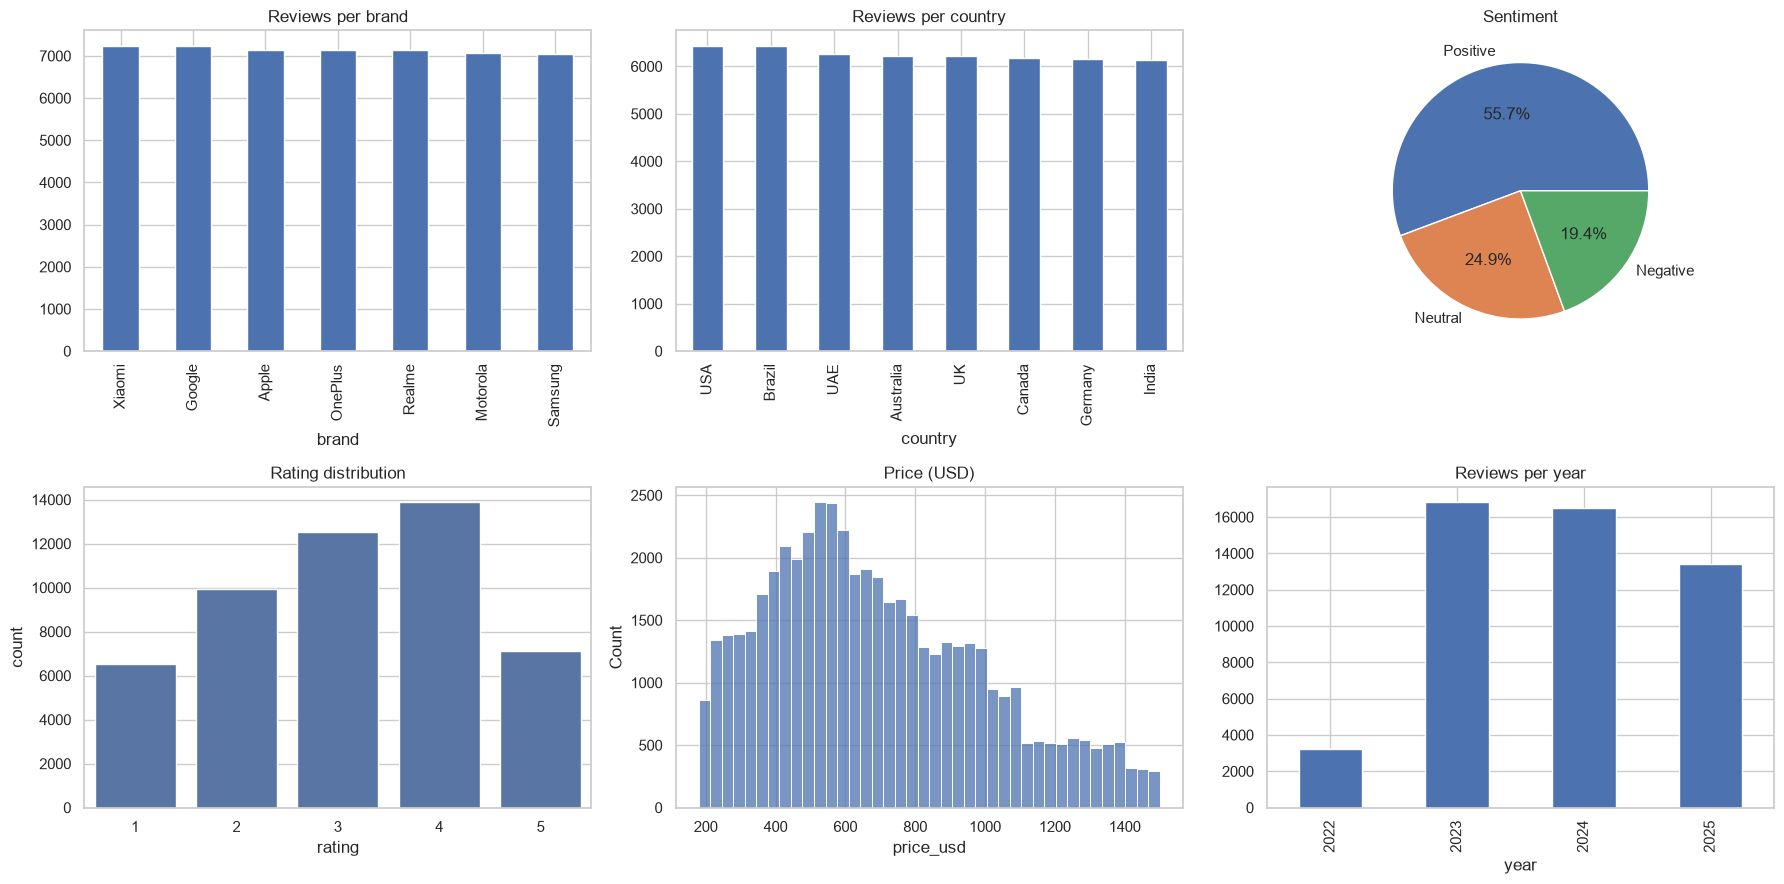

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
df["brand"].value_counts().plot.bar(ax=ax[0,0], title="Reviews per brand")
df["country"].value_counts().plot.bar(ax=ax[0,1], title="Reviews per country")
df["sentiment"].value_counts().plot.pie(ax=ax[0,2], autopct="%1.1f%%", title="Sentiment")
sns.countplot(x="rating", data=df, ax=ax[1,0]); ax[1,0].set_title("Rating distribution")
sns.histplot(df["price_usd"], bins=40, ax=ax[1,1]); ax[1,1].set_title("Price (USD)")
df.groupby("year").size().plot.bar(ax=ax[1,2], title="Reviews per year")
plt.tight_layout(); plt.show()

In [12]:
model_stats = (df.groupby(["brand", "model"])
                 .agg(avg_price=("price_usd", "mean"), avg_rating=("rating", "mean"),
                      reviews=("review_id", "count"), pct_positive=("is_positive", "mean"))
                 .round(3).reset_index().sort_values("avg_rating", ascending=False))
print("Top 5 rated models");    print(model_stats.head(5))
print("Bottom 5 rated models"); print(model_stats.tail(5))
print("\nAverage rating by brand:"); print(df.groupby("brand")["rating"].mean().round(3))
print("\nAverage rating by country:"); print(df.groupby("country")["rating"].mean().round(3))

Top 5 rated models
       brand           model  avg_price  avg_rating  reviews  pct_positive
1      Apple       iPhone 14   1099.212       3.152     1788         0.577
16   Samsung  Galaxy Note 20    899.909       3.132     1789         0.559
0      Apple       iPhone 13   1107.189       3.130     1767         0.574
13    Realme   Realme 12 Pro    394.301       3.126     3535         0.571
8   Motorola    Moto G Power    503.992       3.116     2351         0.563
Bottom 5 rated models
       brand          model  avg_price  avg_rating  reviews  pct_positive
19    Xiaomi      Mi 13 Pro    448.881       3.076     2445         0.556
15   Samsung     Galaxy A55    904.401       3.075     1788         0.553
7   Motorola        Edge 50    508.596       3.069     2315         0.546
2      Apple  iPhone 15 Pro   1103.535       3.061     1793         0.537
17   Samsung     Galaxy S24    894.547       3.053     1761         0.546

Average rating by brand:
brand
Apple       3.107
Google      3.1

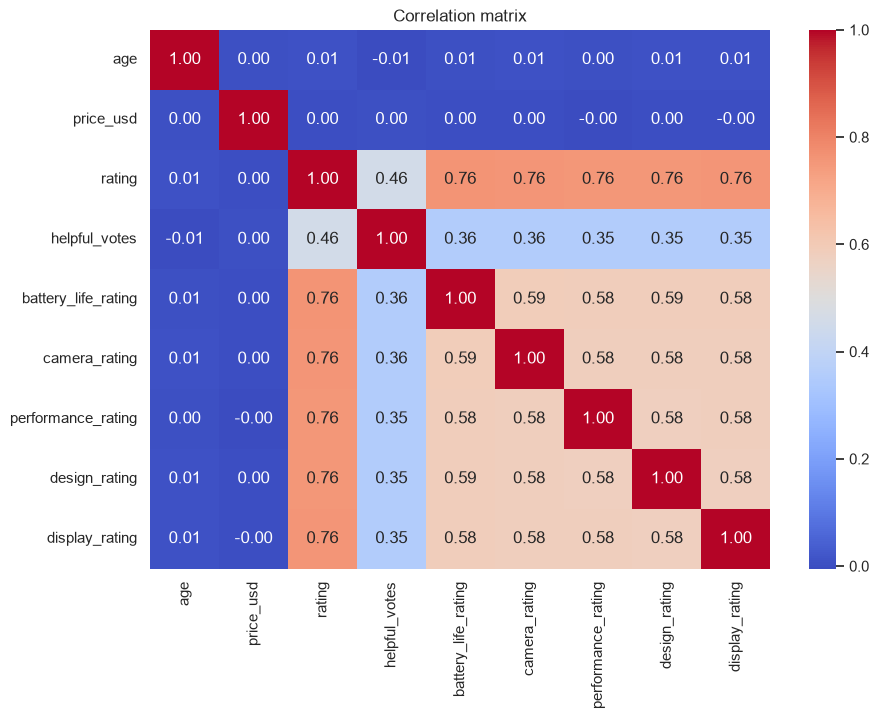

Correlation price_usd vs rating: 0.001
sentiment  Negative  Neutral  Positive
rating                                
1              5126     1373        40
2              3612     5400       932
3               916     4429      7166
4                58     1158     12666
5                 0       77      7047


In [13]:
num_cols = ["age", "price_usd", "rating", "helpful_votes"] + aspect_cols
plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix"); plt.show()
print("Correlation price_usd vs rating: %.3f" % df["price_usd"].corr(df["rating"]))
print(pd.crosstab(df["rating"], df["sentiment"]))

## 6. Customer & Product Segmentation using Clustering

In [14]:
# Product-level table: one row per phone model (22 models)
products = (df.groupby(["brand", "model"])
              .agg(avg_price=("price_usd", "mean"),
                   avg_rating=("rating", "mean"),
                   battery=("battery_life_rating", "mean"),
                   camera=("camera_rating", "mean"),
                   performance=("performance_rating", "mean"),
                   design=("design_rating", "mean"),
                   display=("display_rating", "mean"),
                   pct_positive=("is_positive", "mean"),
                   avg_helpful=("helpful_votes", "mean"),
                   n_reviews=("review_id", "count"))
              .reset_index())
print(products.shape)
products.round(3)

(22, 12)


,brand,model,avg_price,avg_rating,battery,camera,performance,design,display,pct_positive,avg_helpful,n_reviews
0,Apple,iPhone 13,1107.189,3.130,2.755,2.755,2.765,2.765,2.710,0.574,3.743,1767
1,Apple,iPhone 14,1099.212,3.152,2.738,2.782,2.724,2.773,2.759,0.577,3.691,1788
2,Apple,iPhone 15 Pro,1103.535,3.061,2.678,2.707,2.661,2.675,2.691,0.537,3.571,1793
3,Apple,iPhone SE,1103.582,3.085,2.728,2.704,2.732,2.691,2.736,0.549,3.576,1796
4,Google,Pixel 6,808.080,3.092,2.712,2.710,2.690,2.706,2.715,0.564,3.691,2379
5,Google,Pixel 7a,807.311,3.107,2.716,2.732,2.726,2.721,2.749,0.555,3.621,2468
6,Google,Pixel 8,799.294,3.100,2.732,2.716,2.691,2.744,2.738,0.556,3.600,2387
7,Motorola,Edge 50,508.596,3.069,2.675,2.702,2.705,2.689,2.708,0.546,3.632,2315
8,Motorola,Moto G Power,503.992,3.116,2.715,2.706,2.716,2.716,2.719,0.563,3.647,2351
9,Motorola,Razr 40,506.171,3.095,2.713,2.684,2.730,2.725,2.724,0.537,3.633,2395


## 7. Feature Scaling & Encoding Techniques

In [15]:
# Encoding: brand -> one-hot (used by the recommender), model -> label code (lookup id)
products["model_id"] = products["model"].astype("category").cat.codes
brand_dummies = pd.get_dummies(products["brand"], prefix="brand", dtype=int)

# Features used for clustering (numeric only) and scaling
cluster_features = ["avg_price", "avg_rating", "pct_positive", "avg_helpful", "n_reviews"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(products[cluster_features])
print(pd.DataFrame(X_scaled, columns=cluster_features).describe().loc[["mean", "std"]].round(3))

      avg_price  avg_rating  pct_positive  avg_helpful  n_reviews
mean      0.000       0.000         0.000       -0.000      0.000
std       1.024       1.024         1.024        1.024      1.024


## 8. Unsupervised Learning (K-Means Clustering)

   k  inertia  silhouette  davies_bouldin
0  2   75.267       0.233           1.308
1  3   52.582       0.255           1.125
2  4   39.993       0.301           0.937
3  5   29.621       0.290           0.969
4  6   25.263       0.242           1.071
5  7   21.652       0.259           0.810
6  8   18.318       0.230           0.715


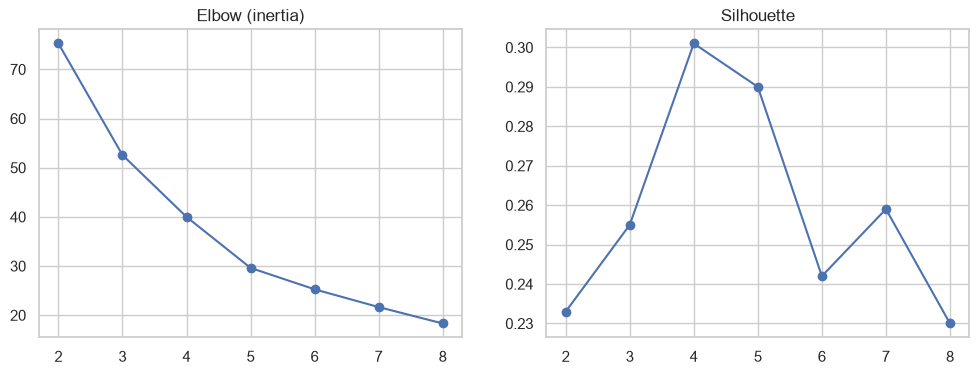

In [16]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    rows.append((k, km.inertia_, silhouette_score(X_scaled, km.labels_), davies_bouldin_score(X_scaled, km.labels_)))
k_eval = pd.DataFrame(rows, columns=["k", "inertia", "silhouette", "davies_bouldin"]).round(3)
print(k_eval)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_eval.k, k_eval.inertia, marker="o"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(k_eval.k, k_eval.silhouette, marker="o"); ax[1].set_title("Silhouette")
plt.show()

In [17]:
K = 4   # as specified in the project brief
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
products["cluster_raw"] = kmeans.labels_
print("Silhouette (k=4): %.3f | Davies-Bouldin: %.3f" % (
    silhouette_score(X_scaled, kmeans.labels_), davies_bouldin_score(X_scaled, kmeans.labels_)))

# Name clusters: two lowest-price clusters are Budget / Mid-range; the two top-price clusters
# have almost identical prices (~$1,001), so they are separated by average rating instead
cm = products.groupby("cluster_raw").agg(price=("avg_price", "mean"), rating=("avg_rating", "mean"))
by_price = cm.sort_values("price").index.tolist()
top_two = cm.loc[by_price[2:]].sort_values("rating", ascending=False).index.tolist()
names = ["Budget", "Mid-range", "Premium (higher-rated)", "Premium (lower-rated)"]
name_map = {by_price[0]: names[0], by_price[1]: names[1], top_two[0]: names[2], top_two[1]: names[3]}
products["segment"] = products["cluster_raw"].map(name_map)
print(products["segment"].value_counts())

Silhouette (k=4): 0.301 | Davies-Bouldin: 0.937
segment
Mid-range                 12
Premium (higher-rated)     4
Premium (lower-rated)      4
Budget                     2
Name: count, dtype: int64


### Customer-level segmentation (review level, 50,000 reviews)

In [18]:
cust_features = ["age", "price_usd", "rating", "helpful_votes", "verified_purchase"]
cs = StandardScaler().fit(df[cust_features])
Xc = cs.transform(df[cust_features])
km_c = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(Xc)
df["customer_cluster"] = km_c.labels_
print("Customer silhouette (sample 10k): %.3f" % silhouette_score(Xc, km_c.labels_, sample_size=10000, random_state=RANDOM_STATE))
cust_profile = df.groupby("customer_cluster").agg(
    size=("review_id", "count"), age=("age", "mean"), price=("price_usd", "mean"),
    rating=("rating", "mean"), helpful=("helpful_votes", "mean"), verified=("verified_purchase", "mean")).round(2)
cust_profile["share_%"] = (cust_profile["size"] / len(df) * 100).round(1)
cust_profile

Customer silhouette (sample 10k): 0.226


,size,age,price,rating,helpful,verified,share_%
customer_cluster,,,,,,,
0,14943,29.97,569.60,2.00,1.84,1.0,29.9
1,9920,30.01,689.54,3.10,3.66,0.0,19.8
2,9469,30.26,1113.11,3.28,3.51,1.0,18.9
3,15668,30.10,548.38,4.04,5.44,1.0,31.3


## 9. Cluster Analysis & Business Insights Generation

In [19]:
profile = (products.groupby("segment")
           .agg(models=("model", "count"), avg_price=("avg_price", "mean"), avg_rating=("avg_rating", "mean"),
                pct_positive=("pct_positive", "mean"), avg_helpful=("avg_helpful", "mean"),
                total_reviews=("n_reviews", "sum"))
           .reindex(names).round(3))
profile["review_share_%"] = (profile["total_reviews"] / profile["total_reviews"].sum() * 100).round(1)
print(profile)
for s in names:
    print(f"{s:10s}:", ", ".join(products.loc[products.segment == s, "model"]))

                        models  avg_price  avg_rating  pct_positive  \
segment                                                               
Budget                       2    393.409       3.119         0.564   
Mid-range                   12    608.348       3.099         0.555   
Premium (higher-rated)       4   1001.257       3.132         0.568   
Premium (lower-rated)        4   1001.516       3.068         0.546   

                        avg_helpful  total_reviews  review_share_%  
segment                                                             
Budget                        3.665           7132            14.3  
Mid-range                     3.639          28672            57.3  
Premium (higher-rated)        3.689           7058            14.1  
Premium (lower-rated)         3.601           7138            14.3  
Budget    : Realme 12 Pro, Realme Narzo 70
Mid-range : Pixel 6, Pixel 7a, Pixel 8, Edge 50, Moto G Power, Razr 40, OnePlus 11R, OnePlus 12, OnePlus Nord 3, Mi 

In [20]:
# Key insights, computed rather than typed
best  = products.sort_values("avg_rating", ascending=False).iloc[0]
worst = products.sort_values("avg_rating").iloc[0]
print("Highest rated model: %s (%.3f)  | lowest: %s (%.3f)" % (best.model, best.avg_rating, worst.model, worst.avg_rating))
print("Rating spread across all 22 models: %.3f" % (products.avg_rating.max() - products.avg_rating.min()))
print("Price vs rating correlation (models): %.3f" % products["avg_price"].corr(products["avg_rating"]))
print("Price vs rating correlation (reviews): %.3f" % df["price_usd"].corr(df["rating"]))
print("Most reviewed:", products.sort_values("n_reviews", ascending=False).iloc[0][["model", "n_reviews"]].tolist())
print(df.groupby("source")["rating"].mean().round(3).to_dict())

Highest rated model: iPhone 14 (3.152)  | lowest: Galaxy S24 (3.053)
Rating spread across all 22 models: 0.099
Price vs rating correlation (models): 0.010
Price vs rating correlation (reviews): 0.001
Most reviewed: ['Realme Narzo 70', np.int64(3597)]
{'AliExpress': 3.115, 'Amazon': 3.111, 'BestBuy': 3.099, 'Flipkart': 3.097, 'Unknown': 3.088, 'eBay': 3.092}


## 10. Similarity-Based Recommendation System

In [21]:
feat_cols = ["avg_price", "avg_rating", "battery", "camera", "performance", "design", "display", "pct_positive"]
weights = pd.Series({"avg_price": 2.0, "avg_rating": 1.5, "battery": 1, "camera": 1, "performance": 1,
                     "design": 1, "display": 1, "pct_positive": 1})
Xf = StandardScaler().fit_transform(products[feat_cols]) * weights.values
Xf = np.hstack([Xf, brand_dummies.values * 0.5])          # small same-brand bonus
sim_content = pd.DataFrame(cosine_similarity(Xf), index=products["model"], columns=products["model"])

def recommend(model_name, n=5, same_segment_only=False, max_price_diff=None):
    base = products.set_index("model").loc[model_name]
    s = sim_content[model_name].drop(model_name)
    out = products.set_index("model").loc[s.index, ["brand", "avg_price", "avg_rating", "segment"]].assign(similarity=s.round(3))
    if same_segment_only: out = out[out["segment"] == base["segment"]]
    if max_price_diff is not None: out = out[(out["avg_price"] - base["avg_price"]).abs() <= max_price_diff]
    return out.sort_values("similarity", ascending=False).head(n).round(2)

recommend("iPhone 15 Pro")

,brand,avg_price,avg_rating,segment,similarity
model,,,,,
Galaxy S24,Samsung,894.55,3.05,Premium (lower-rated),0.86
Galaxy A55,Samsung,904.40,3.07,Premium (lower-rated),0.70
iPhone SE,Apple,1103.58,3.08,Premium (lower-rated),0.64
Pixel 6,Google,808.08,3.09,Mid-range,0.56
Edge 50,Motorola,508.60,3.07,Mid-range,0.39


In [22]:
# Validation: how often do the top-3 recommendations stay in the same cluster / close in price?
seg = products.set_index("model")["segment"]; price = products.set_index("model")["avg_price"]
same_seg, price_gap = [], []
for m in products["model"]:
    top = sim_content[m].drop(m).nlargest(3).index
    same_seg += [seg[t] == seg[m] for t in top]
    price_gap += [abs(price[t] - price[m]) for t in top]
print("Top-3 recommendations in same segment: %.1f%%" % (100 * np.mean(same_seg)))
print("Mean absolute price gap of top-3 recommendations: $%.0f (vs $%.0f for random pairs)" % (
    np.mean(price_gap), np.mean([abs(a - b) for i, a in enumerate(price) for j, b in enumerate(price) if i != j])))

Top-3 recommendations in same segment: 59.1%
Mean absolute price gap of top-3 recommendations: $131 (vs $290 for random pairs)


## 11. Collaborative Filtering Basics

In [23]:
# The data has no persistent user id (customer_name is not unique per person), so we build
# 'pseudo-users' = country x age group (8 x 4 = 32 groups) and do ITEM-ITEM collaborative filtering
df["pseudo_user"] = df["country"] + "|" + df["age_group"].astype(str)
ui = df.pivot_table(index="pseudo_user", columns="model", values="rating", aggfunc="mean")
print("User-item matrix:", ui.shape, "| missing cells:", int(ui.isna().sum().sum()))

ui_centered = ui.sub(ui.mean(axis=1), axis=0).fillna(0)         # mean-centre per pseudo-user
sim_cf = pd.DataFrame(cosine_similarity(ui_centered.T), index=ui.columns, columns=ui.columns)

def recommend_cf(model_name, n=5):
    return sim_cf[model_name].drop(model_name).nlargest(n).round(3)

print(recommend_cf("iPhone 15 Pro"))

def recommend_hybrid(model_name, n=5, alpha=0.7):
    s = alpha * sim_content[model_name] + (1 - alpha) * sim_cf[model_name]
    return s.drop(model_name).nlargest(n).round(3)

overlap = np.mean([len(set(sim_content[m].drop(m).nlargest(5).index) & set(sim_cf[m].drop(m).nlargest(5).index)) / 5
                   for m in products["model"]])
print("Average top-5 overlap between content-based and CF lists: %.1f%%" % (100 * overlap))

User-item matrix: (32, 22) | missing cells: 0
model
Galaxy A55        0.388
Galaxy Note 20    0.388
OnePlus 12        0.379
Pixel 7a          0.275
Galaxy Z Flip     0.137
Name: iPhone 15 Pro, dtype: float64
Average top-5 overlap between content-based and CF lists: 28.2%


## 12. Data Visualization (Seaborn / Matplotlib / Plotly)

PCA explained variance: 83.2%


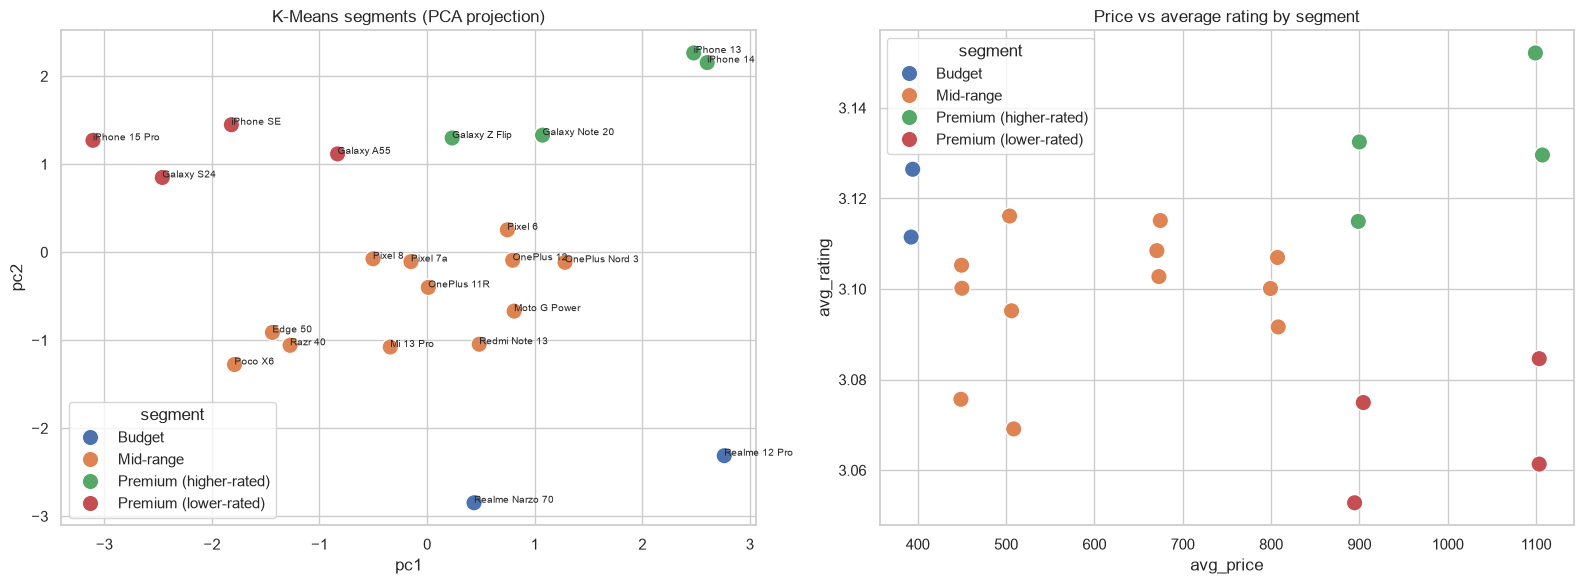

In [24]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pts = pca.fit_transform(X_scaled)
products["pc1"], products["pc2"] = pts[:, 0], pts[:, 1]
print("PCA explained variance: %.1f%%" % (100 * pca.explained_variance_ratio_.sum()))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=products, x="pc1", y="pc2", hue="segment", hue_order=names, s=140, ax=ax[0])
for _, r in products.iterrows(): ax[0].annotate(r["model"], (r["pc1"], r["pc2"]), fontsize=7)
ax[0].set_title("K-Means segments (PCA projection)")
sns.scatterplot(data=products, x="avg_price", y="avg_rating", hue="segment", hue_order=names, s=140, ax=ax[1])
ax[1].set_title("Price vs average rating by segment")
plt.tight_layout(); plt.show()

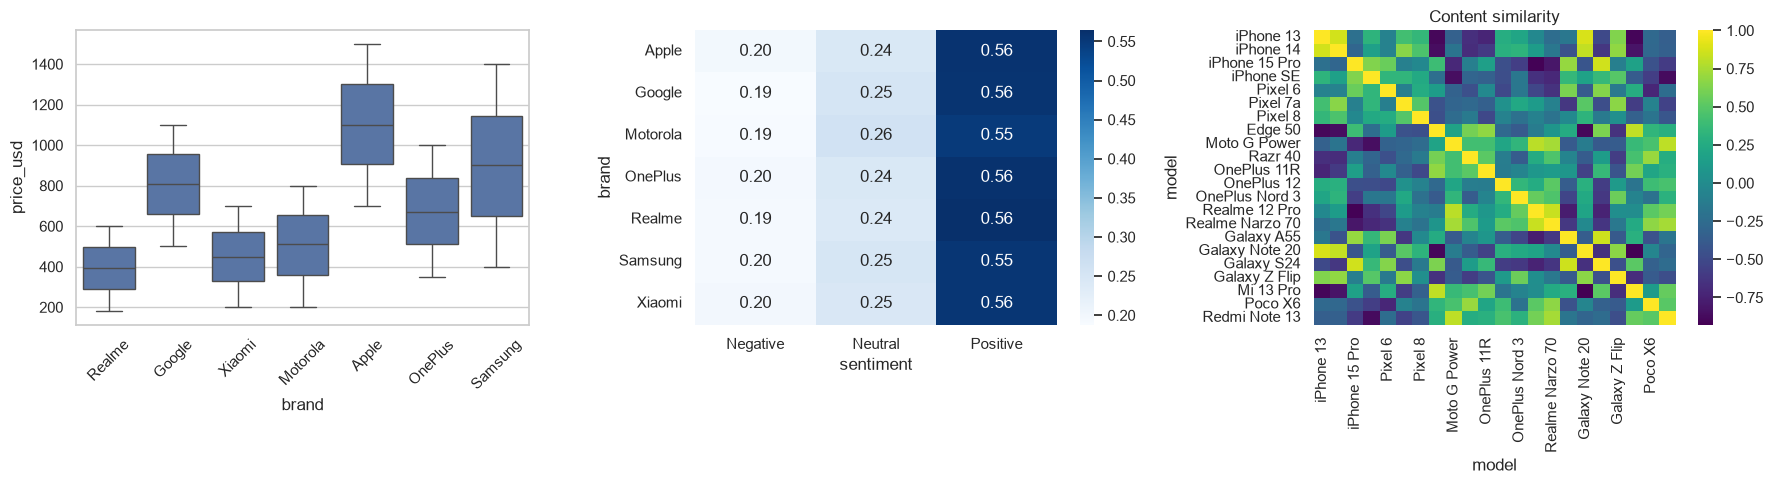

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x="brand", y="price_usd", ax=ax[0]); ax[0].tick_params(axis="x", rotation=45)
sns.heatmap(pd.crosstab(df["brand"], df["sentiment"], normalize="index").round(3), annot=True, fmt=".2f", cmap="Blues", ax=ax[1])
sns.heatmap(sim_content, cmap="viridis", ax=ax[2]); ax[2].set_title("Content similarity")
plt.tight_layout(); plt.show()
# Plotly versions of these charts are used inside the Streamlit app (section 13).

## 13. Web App Development using Streamlit

In [26]:
products.to_csv("products_segmented.csv", index=False)
sim_content.to_csv("sim_content.csv")
sim_cf.to_csv("sim_cf.csv")
df[["model","brand","country","rating","price_usd","sentiment","age_group"]].to_csv("reviews_slim.csv", index=False)
print("Saved: products_segmented.csv, sim_content.csv, sim_cf.csv, reviews_slim.csv")

Saved: products_segmented.csv, sim_content.csv, sim_cf.csv, reviews_slim.csv


## 15. End-to-End Machine Learning Pipeline

In [28]:
def run_pipeline(path, k=4):
    d = pd.read_csv(path).drop_duplicates()
    d["pl"] = pd.to_numeric(d["price_local"].str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
    d["price_usd"] = d["price_usd"].fillna(d["pl"] / d["exchange_rate_to_usd"])
    d["price_usd"] = d["price_usd"].fillna(d.groupby("model")["price_usd"].transform("median"))
    d["rating"] = d["rating"].fillna(d[aspect_cols].mean(axis=1).round())
    d["is_positive"] = (d["sentiment"].fillna(d["rating"].map(mode_map)) == "Positive").astype(int)
    p = d.groupby(["brand", "model"]).agg(avg_price=("price_usd", "mean"), avg_rating=("rating", "mean"),
            pct_positive=("is_positive", "mean"), avg_helpful=("helpful_votes", "mean"),
            n_reviews=("review_id", "count")).reset_index()
    Xs = StandardScaler().fit_transform(p[cluster_features])
    p["cluster"] = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(Xs)
    return p

check = run_pipeline("Mobile Reviews Sentiment null.csv") 
print(check.groupby("cluster")[["avg_price", "avg_rating"]].mean().round(2))

         avg_price  avg_rating
cluster                       
0          1001.52        3.07
1          1001.26        3.13
2           393.41        3.12
3           608.35        3.10
